# Project Task 02 — Data Understanding, EDA, dan Persiapan Data Awal
## Topik: Aktivitas Transaksi Digital yang Tidak Wajar

| | |
|---|---|
| **Project ID** | `[ISI PROJECT ID KELOMPOK]` |
| **Kelompok** | `[ISI NAMA KELOMPOK]` |
| **Anggota** | `[ISI NAMA & NIM ANGGOTA]` |
| **Dataset** | PaySim — Synthetic Financial Datasets For Fraud Detection (Kaggle) |

> **Sebelum dikumpulkan:** (1) isi Project ID, nama kelompok, dan anggota; (2) jalankan seluruh sel dari atas (*Restart & Run All*);
> (3) cocokkan teks pada bagian **Interpretasi** dengan angka pada output di sel sebelumnya, lalu sesuaikan jika berbeda.

**Isi notebook:** Project Identification → Problem Formulation → Dataset dan Sumber → Data Understanding → EDA →
Data Quality Findings → Preprocessing Plan → Initial Feature Engineering → Initial Data Pipeline → Kesimpulan dan Rencana Tahap Berikutnya.

In [1]:
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

---
## 1. Project Identification

| Komponen | Isi |
|---|---|
| **Project ID** | `[ISI PROJECT ID KELOMPOK]` |
| **Topik project** | Aktivitas Transaksi Digital yang Tidak Wajar |
| **Masalah yang ingin dikaji** | Transaksi digital (transfer, tarik tunai, pembayaran) yang mengandung penipuan (*fraud*) jumlahnya sangat sedikit dan tersembunyi di antara jutaan transaksi normal, sehingga sulit ditemukan dengan pemeriksaan manual atau aturan sederhana. |
| **Tujuan project** | Memahami karakteristik transaksi yang tidak wajar dan membangun dasar data yang siap dipakai untuk model Machine Learning pendeteksi transaksi fraud/anomali. |
| **Unit analisis** | Satu transaksi digital (satu baris data). |
| **Target/variabel yang dianalisis** | `isFraud` (1 = transaksi fraud, 0 = transaksi normal). Variabel pendukung: `type`, `amount`, `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`, `step`. |

**Pertanyaan utama:** *Masalah apa yang ingin kami pahami atau selesaikan dengan Machine Learning?*
Kami ingin mengetahui **ciri-ciri apa yang membedakan transaksi tidak wajar (fraud) dari transaksi normal**, dan
bagaimana data harus disiapkan agar model dapat mengenali ciri tersebut meskipun fraud sangat langka.

---
## 2. Problem Formulation

- **Rumusan masalah:** Bagaimana mengidentifikasi transaksi digital yang tidak wajar (fraud) berdasarkan tipe transaksi,
  nominal, perubahan saldo pengirim/penerima, dan waktu transaksi?
- **Jenis tugas ML (rencana):** klasifikasi biner (*fraud* vs *normal*) dengan `isFraud` sebagai label; pendekatan
  *anomaly detection* (mis. Isolation Forest) dapat dipertimbangkan sebagai pembanding pada tahap berikutnya.
- **Mengapa penting:** fraud menimbulkan kerugian finansial langsung dan menurunkan kepercayaan pengguna layanan keuangan digital.
- **Tantangan utama:** kelas sangat tidak seimbang (*imbalanced*), nilai transaksi sangat miring (*skewed*), dan akurasi
  saja tidak cukup sebagai ukuran keberhasilan.
- **Rencana metrik evaluasi (tahap modeling nanti):** Precision, Recall, F1-score, dan PR-AUC — bukan akurasi.
- **Batasan tahap ini:** belum ada pemilihan algoritma, tuning, maupun deployment. Fokus pada pemahaman dan persiapan data.

---
## 3. Dataset dan Sumber

**Dataset:** *Synthetic Financial Datasets For Fraud Detection* (PaySim).
**Sumber:** Kaggle — <https://www.kaggle.com/datasets/ealaxi/paysim1>

Dataset dibangkitkan oleh simulator **PaySim**, yang memakai data agregat dari log transaksi *mobile money* nyata di sebuah negara
Afrika, lalu menyuntikkan perilaku berbahaya (fraud) untuk keperluan evaluasi metode deteksi. Data keuangan asli bersifat privat,
sehingga dataset sintetis seperti ini sering dipakai sebagai pengganti untuk riset deteksi fraud.

*Rujukan:* E. A. Lopez-Rojas, A. Elmir, S. Axelsson, **"PaySim: A financial mobile money simulator for fraud detection"**, 2016.

**Mengapa dataset ini sesuai dengan topik:**
1. Berisi transaksi digital (transfer, cash-out, cash-in, pembayaran, debit) — sesuai dengan "aktivitas transaksi digital".
2. Memiliki label `isFraud`, sehingga transaksi "tidak wajar" terdefinisi jelas dan dapat dievaluasi.
3. Jumlah data besar (jutaan baris) dan variabelnya dapat diinterpretasi (jenis transaksi, nominal, saldo).
4. Sumber, deskripsi, dan atribut terdokumentasi dengan jelas di Kaggle.

**Kamus variabel:**

| Variabel | Deskripsi |
|---|---|
| `step` | Satuan waktu simulasi: 1 step = 1 jam (total 744 step ≈ 30 hari). |
| `type` | Jenis transaksi: `CASH_IN`, `CASH_OUT`, `DEBIT`, `PAYMENT`, `TRANSFER`. |
| `amount` | Nominal transaksi dalam mata uang lokal. |
| `nameOrig` | ID pelanggan pengirim/pemulai transaksi. |
| `oldbalanceOrg` | Saldo pengirim sebelum transaksi. |
| `newbalanceOrig` | Saldo pengirim setelah transaksi. |
| `nameDest` | ID penerima (prefix `C` = customer, `M` = merchant). |
| `oldbalanceDest` | Saldo penerima sebelum transaksi (tidak tersedia untuk merchant). |
| `newbalanceDest` | Saldo penerima setelah transaksi (tidak tersedia untuk merchant). |
| `isFraud` | **Target**: 1 jika transaksi dilakukan oleh agen fraud dalam simulasi. |
| `isFlaggedFraud` | Penanda dari aturan bisnis sederhana (menandai transfer bernilai sangat besar dalam satu transaksi). |

In [3]:
# Jika RAM terbatas, isi NROWS (mis. 500_000). Catatan: file terurut menurut 'step',
# sehingga NROWS hanya mengambil jam-jam awal. Gunakan None untuk memuat seluruh data.
NROWS = None


def cari_file_paysim():
    pola = ["PS_*.csv", "data/PS_*.csv", "../data/PS_*.csv", "**/PS_*.csv"]
    for p in pola:
        hasil = glob.glob(p, recursive=True)
        if hasil:
            return hasil[0]
    # Alternatif: unduh otomatis lewat kagglehub (butuh `pip install kagglehub` dan akun Kaggle)
    try:
        import kagglehub

        folder = kagglehub.dataset_download("ealaxi/paysim1")
        hasil = glob.glob(os.path.join(folder, "*.csv"))
        if hasil:
            return hasil[0]
    except Exception as e:
        print("Unduh otomatis via kagglehub tidak berhasil:", e)
    raise FileNotFoundError(
        "File PaySim tidak ditemukan. Unduh dari https://www.kaggle.com/datasets/ealaxi/paysim1 "
        "lalu letakkan file CSV (PS_...log.csv) di folder yang sama dengan notebook ini."
    )


DATA_PATH = cari_file_paysim()
df = pd.read_csv(DATA_PATH, nrows=NROWS)
print("File data :", DATA_PATH)
df.head()

100%|██████████| 178M/178M [00:12<00:00, 15.5MB/s] 

Extracting files...


File data : C:\Users\aswan\.cache\kagglehub\datasets\ealaxi\paysim1\versions\2\PS_20174392719_1491204439457_log.csv


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.640",C1231006815,"170,136.000","160,296.360",M1979787155,0.000,0.000,0,0
1,1,PAYMENT,"1,864.280",C1666544295,"21,249.000","19,384.720",M2044282225,0.000,0.000,0,0
2,1,TRANSFER,181.000,C1305486145,181.000,0.000,C553264065,0.000,0.000,1,0
3,1,CASH_OUT,181.000,C840083671,181.000,0.000,C38997010,"21,182.000",0.000,1,0
4,1,PAYMENT,"11,668.140",C2048537720,"41,554.000","29,885.860",M1230701703,0.000,0.000,0,0


In [4]:
dokumentasi = pd.DataFrame(
    {
        "Informasi": [
            "Nama dataset", "Sumber", "Link sumber", "Jumlah baris", "Jumlah kolom",
            "Variabel utama", "Target", "Jenis data", "Lisensi/keterangan penggunaan",
        ],
        "Keterangan": [
            "Synthetic Financial Datasets For Fraud Detection (PaySim)",
            "Kaggle (E. A. Lopez-Rojas et al., simulator PaySim)",
            "https://www.kaggle.com/datasets/ealaxi/paysim1",
            f"{df.shape[0]:,}",
            f"{df.shape[1]}",
            "type, amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, step",
            "isFraud (0 = normal, 1 = fraud)",
            "Numerik + Kategorikal (tidak ada teks bebas)",
            "Data sintetis untuk riset/pembelajaran; cek lisensi terbaru pada halaman Kaggle dan cantumkan sitasi.",
        ],
    }
).set_index("Informasi")
dokumentasi

,Keterangan
Informasi,
Nama dataset,Synthetic Financial Datasets For Fraud Detecti...
Sumber,"Kaggle (E. A. Lopez-Rojas et al., simulator Pa..."
Link sumber,https://www.kaggle.com/datasets/ealaxi/paysim1
Jumlah baris,"6,362,620"
Jumlah kolom,11
Variabel utama,"type, amount, oldbalanceOrg, newbalanceOrig, o..."
Target,"isFraud (0 = normal, 1 = fraud)"
Jenis data,Numerik + Kategorikal (tidak ada teks bebas)
Lisensi/keterangan penggunaan,Data sintetis untuk riset/pembelajaran; cek li...


---
## 4. Data Understanding

### 4.1 Struktur data

In [5]:
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")

struktur = pd.DataFrame(
    {
        "tipe_data": df.dtypes.astype(str),
        "n_unik": df.nunique(),
        "n_missing": df.isna().sum(),
        "contoh_nilai": df.iloc[0],
    }
)
struktur

Jumlah baris : 6,362,620
Jumlah kolom : 11


,tipe_data,n_unik,n_missing,contoh_nilai
step,int64,743,0,1
type,str,5,0,PAYMENT
amount,float64,5316900,0,"9,839.640"
nameOrig,str,6353307,0,C1231006815
oldbalanceOrg,float64,1845844,0,"170,136.000"
newbalanceOrig,float64,2682586,0,"160,296.360"
nameDest,str,2722362,0,M1979787155
oldbalanceDest,float64,3614697,0,0.000
newbalanceDest,float64,3555499,0,0.000
isFraud,int64,2,0,0


In [6]:
kolom_numerik = ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
kolom_kategorikal = ["type"]
kolom_id = ["nameOrig", "nameDest"]           # pengenal akun (kardinalitas sangat tinggi)
kolom_target = "isFraud"                      # biner
kolom_flag = "isFlaggedFraud"                 # biner (hasil aturan sederhana)

print("Variabel numerik     :", kolom_numerik)
print("Variabel kategorikal :", kolom_kategorikal, "+ biner:", [kolom_target, kolom_flag])
print("Variabel pengenal    :", kolom_id)
print("Variabel teks bebas  : tidak ada")

df.sample(5, random_state=RANDOM_STATE)

Variabel numerik     : ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Variabel kategorikal : ['type'] + biner: ['isFraud', 'isFlaggedFraud']
Variabel pengenal    : ['nameOrig', 'nameDest']
Variabel teks bebas  : tidak ada


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
3737323,278,CASH_IN,"330,218.420",C632336343,"20,866.000","351,084.420",C834976624,"452,419.570","122,201.150",0,0
264914,15,PAYMENT,"11,647.080",C1264712553,"30,370.000","18,722.920",M215391829,0.000,0.000,0,0
85647,10,CASH_IN,"152,264.210",C1746846248,"106,589.000","258,853.210",C1607284477,"201,303.010","49,038.800",0,0
5899326,403,TRANSFER,"1,551,760.630",C333676753,0.000,0.000,C1564353608,"3,198,359.450","4,750,120.080",0,0
2544263,206,CASH_IN,"78,172.300",C813403091,"2,921,331.580","2,999,503.880",C1091768874,"415,821.900","337,649.600",0,0


### 4.2 Statistik dasar — variabel numerik

In [7]:
statistik = df[kolom_numerik].describe().T
statistik["median"] = df[kolom_numerik].median()
statistik["IQR"] = statistik["75%"] - statistik["25%"]
statistik["skewness"] = df[kolom_numerik].skew()
statistik[["count", "mean", "median", "std", "min", "25%", "75%", "max", "IQR", "skewness"]]

,count,mean,median,std,min,25%,75%,max,IQR,skewness
step,"6,362,620.000",243.397,239.000,142.332,1.000,156.000,335.000,743.000,179.000,0.375
amount,"6,362,620.000","179,861.904","74,871.940","603,858.231",0.000,"13,389.570","208,721.478","92,445,516.640","195,331.908",30.994
oldbalanceOrg,"6,362,620.000","833,883.104","14,208.000","2,888,242.673",0.000,0.000,"107,315.175","59,585,040.370","107,315.175",5.249
newbalanceOrig,"6,362,620.000","855,113.669",0.000,"2,924,048.503",0.000,0.000,"144,258.410","49,585,040.370","144,258.410",5.177
oldbalanceDest,"6,362,620.000","1,100,701.667","132,705.665","3,399,180.113",0.000,0.000,"943,036.708","356,015,889.350","943,036.708",19.922
newbalanceDest,"6,362,620.000","1,224,996.398","214,661.440","3,674,128.942",0.000,0.000,"1,111,909.250","356,179,278.920","1,111,909.250",19.352


### 4.3 Statistik dasar — variabel kategorikal

In [8]:
for kol in ["type", "isFraud", "isFlaggedFraud"]:
    frek = df[kol].value_counts()
    tabel = pd.DataFrame({"frekuensi": frek, "persen (%)": frek / len(df) * 100})
    print(f"\n=== {kol} | jumlah kategori: {df[kol].nunique()} ===")
    display(tabel)

print("\nKardinalitas ID akun:")
print(" nameOrig :", f"{df['nameOrig'].nunique():,}", "ID unik")
print(" nameDest :", f"{df['nameDest'].nunique():,}", "ID unik")

print("\nJenis penerima (prefix nameDest):")
display(df["nameDest"].str[0].value_counts().rename("frekuensi").to_frame())


=== type | jumlah kategori: 5 ===


,frekuensi,persen (%)
type,,
CASH_OUT,2237500,35.166
PAYMENT,2151495,33.815
CASH_IN,1399284,21.992
TRANSFER,532909,8.376
DEBIT,41432,0.651



=== isFraud | jumlah kategori: 2 ===


,frekuensi,persen (%)
isFraud,,
0,6354407,99.871
1,8213,0.129



=== isFlaggedFraud | jumlah kategori: 2 ===


,frekuensi,persen (%)
isFlaggedFraud,,
0,6362604,100.000
1,16,0.000



Kardinalitas ID akun:
 nameOrig : 6,353,307 ID unik
 nameDest : 2,722,362 ID unik

Jenis penerima (prefix nameDest):


,frekuensi
nameDest,
C,4211125
M,2151495


**Ringkasan Data Understanding**
- Data terdiri dari variabel numerik (nominal, saldo, waktu), satu variabel kategorikal (`type`), dua pengenal akun, dan dua variabel biner (`isFraud`, `isFlaggedFraud`).
- `type` memiliki 5 kategori; kategori dominan dan yang sangat jarang (mis. `DEBIT`) dapat dilihat pada tabel frekuensi di atas.
- `isFraud` jauh lebih jarang daripada kelas normal → masalah **ketidakseimbangan kelas**.
- `nameOrig` dan `nameDest` memiliki kardinalitas sangat tinggi sehingga tidak layak di-*encode* langsung.

---
## 5. Exploratory Data Analysis (EDA)

Setiap visualisasi diikuti format **Temuan → Bukti → Interpretasi → Implikasi**.
Untuk grafik yang berat (histogram, scatter), digunakan sampel acak agar notebook tetap ringan; angka "Bukti" dihitung dari **seluruh data** jika memungkinkan.

> Catatan: teks *Interpretasi* ditulis berdasarkan karakteristik umum PaySim. Cocokkan dengan angka pada output sebelum dikumpulkan.

In [9]:
df_s = df.sample(n=min(300_000, len(df)), random_state=RANDOM_STATE)
print("Ukuran sampel EDA:", len(df_s))

Ukuran sampel EDA: 300000


### 5.1 Distribusi `amount` (histogram dan boxplot)

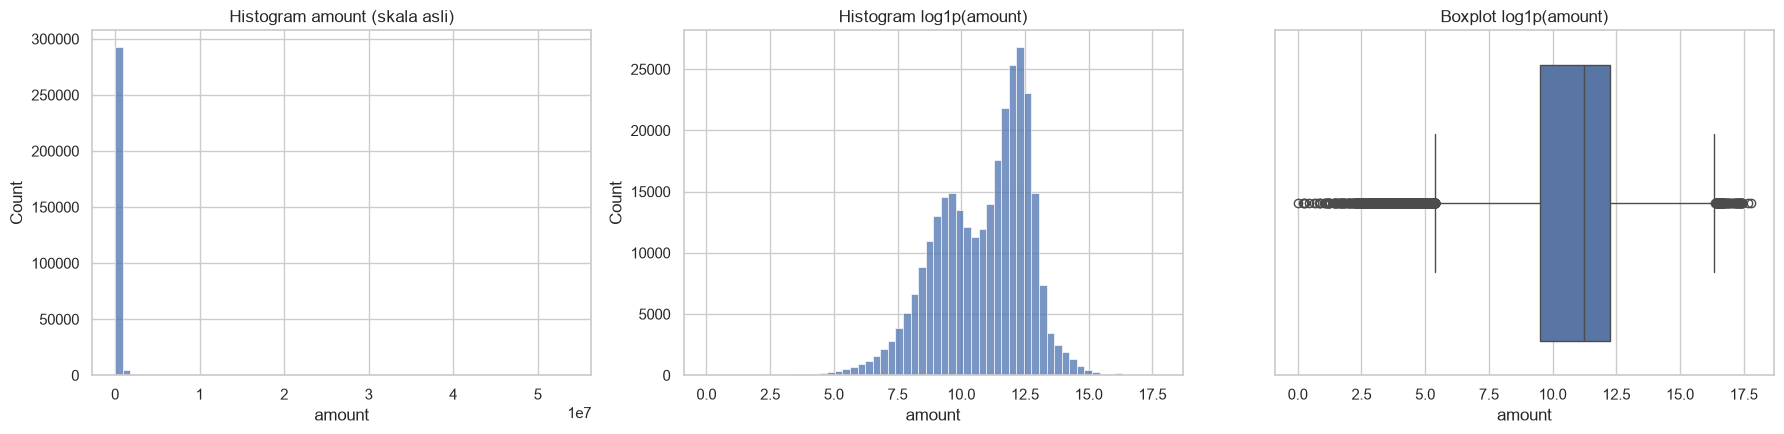

Mean amount   : 179,861.90
Median amount : 74,871.94
Skewness      : 30.99
Batas atas outlier (Q3 + 1.5*IQR): 501,719.34
Transaksi di atas batas: 5.31% dari seluruh data


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

sns.histplot(df_s["amount"], bins=60, ax=ax[0])
ax[0].set_title("Histogram amount (skala asli)")

sns.histplot(np.log1p(df_s["amount"]), bins=60, ax=ax[1])
ax[1].set_title("Histogram log1p(amount)")

sns.boxplot(x=np.log1p(df_s["amount"]), ax=ax[2])
ax[2].set_title("Boxplot log1p(amount)")

plt.tight_layout()
plt.show()

q1, q3 = df["amount"].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
print(f"Mean amount   : {df['amount'].mean():,.2f}")
print(f"Median amount : {df['amount'].median():,.2f}")
print(f"Skewness      : {df['amount'].skew():.2f}")
print(f"Batas atas outlier (Q3 + 1.5*IQR): {batas_atas:,.2f}")
print(f"Transaksi di atas batas: {(df['amount'] > batas_atas).mean() * 100:.2f}% dari seluruh data")

- **Temuan:** Distribusi `amount` sangat condong ke kanan; sebagian besar transaksi bernilai kecil–menengah, sebagian kecil sangat besar.
- **Bukti:** Histogram skala asli menumpuk di dekat nol dengan ekor panjang; *mean* jauh lebih besar dari *median*, *skewness* tinggi, dan ada persentase transaksi di atas batas IQR (lihat output).
- **Interpretasi:** Ini pola umum data finansial. Nilai ekstrem belum tentu salah input — bisa transaksi sah bernilai besar, bisa juga perilaku mencurigakan.
- **Implikasi:** Gunakan transformasi `log1p` dan *scaler* yang tahan outlier (`RobustScaler`). Outlier **tidak dibuang** karena bisa jadi justru sinyal fraud (dibuktikan lagi di bagian 6).

### 5.2 Distribusi jenis transaksi dan proporsi fraud per jenis (bar chart)

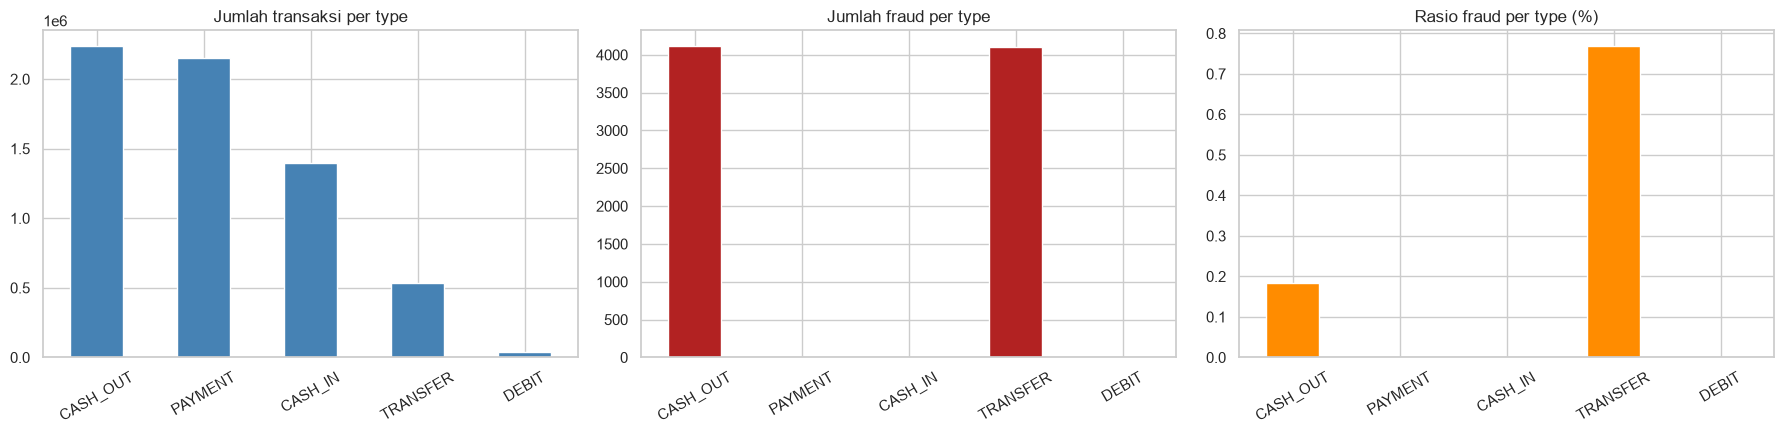

,jumlah_transaksi,jumlah_fraud,rasio_fraud,rasio_fraud (%)
type,,,,
CASH_OUT,2237500,4116,0.002,0.184
PAYMENT,2151495,0,0.000,0.000
CASH_IN,1399284,0,0.000,0.000
TRANSFER,532909,4097,0.008,0.769
DEBIT,41432,0,0.000,0.000


In [11]:
ringkas_type = df.groupby("type")["isFraud"].agg(jumlah_transaksi="size", jumlah_fraud="sum", rasio_fraud="mean")
ringkas_type["rasio_fraud (%)"] = ringkas_type["rasio_fraud"] * 100
ringkas_type = ringkas_type.sort_values("jumlah_transaksi", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ringkas_type["jumlah_transaksi"].plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Jumlah transaksi per type")
ringkas_type["jumlah_fraud"].plot.bar(ax=ax[1], color="firebrick")
ax[1].set_title("Jumlah fraud per type")
ringkas_type["rasio_fraud (%)"].plot.bar(ax=ax[2], color="darkorange")
ax[2].set_title("Rasio fraud per type (%)")
for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

ringkas_type

- **Temuan:** Transaksi didominasi beberapa jenis tertentu, dan fraud hanya muncul pada jenis tertentu (umumnya `TRANSFER` dan `CASH_OUT`); rasio fraud pada `TRANSFER` jauh lebih tinggi dibanding jenis lain.
- **Bukti:** Tabel dan bar chart di atas — jumlah fraud untuk `PAYMENT`, `CASH_IN`, dan `DEBIT` sama dengan nol (atau mendekati nol).
- **Interpretasi:** Skema fraud pada simulasi adalah mengambil alih akun lalu memindahkan dana (`TRANSFER`) dan menarik tunai (`CASH_OUT`). Jenis transaksi lain tidak relevan untuk pola ini.
- **Implikasi:** `type` adalah fitur penting. Ruang lingkup pemodelan dapat dipersempit ke `TRANSFER` dan `CASH_OUT` untuk mengurangi *noise* dan ukuran data (dipakai pada pipeline bagian 9).

### 5.3 Nominal transaksi: fraud vs normal (boxplot)

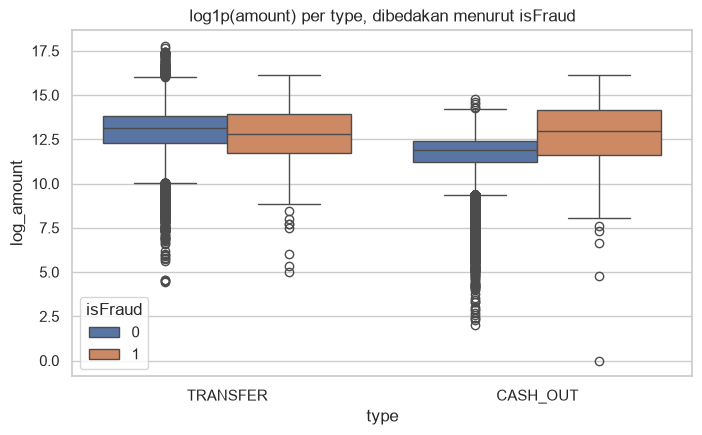

                     size      median          mean
type     isFraud                                   
CASH_OUT 0        2233384 146,946.560   173,917.156
         1           4116 435,516.905 1,455,102.586
TRANSFER 0         528812 486,521.910   906,229.008
         1           4097 445,705.760 1,480,891.673


In [12]:
sub_tc = df_s[df_s["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
sub_tc["log_amount"] = np.log1p(sub_tc["amount"])

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=sub_tc, x="type", y="log_amount", hue="isFraud")
plt.title("log1p(amount) per type, dibedakan menurut isFraud")
plt.show()

full_tc = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
print(full_tc.groupby(["type", "isFraud"])["amount"].agg(["size", "median", "mean"]))

- **Temuan:** Pada `TRANSFER` dan `CASH_OUT`, nominal transaksi fraud cenderung lebih besar daripada transaksi normal.
- **Bukti:** Posisi kotak (median) kelas fraud pada boxplot lebih tinggi; tabel median/mean memperkuat perbedaan tersebut.
- **Interpretasi:** Pelaku fraud memindahkan nominal besar sekaligus. Namun sebaran kedua kelas masih tumpang tindih, sehingga `amount` saja tidak cukup untuk memisahkan fraud.
- **Implikasi:** `amount` dipakai bersama fitur lain (rasio terhadap saldo, perubahan saldo) — lihat Feature Engineering (bagian 8).

### 5.4 Hubungan `oldbalanceOrg` dan `amount` (scatter plot)

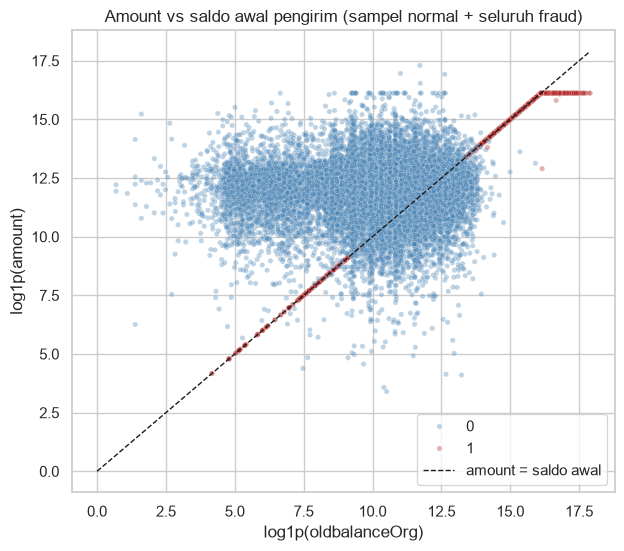

Persentase transaksi yang menguras seluruh saldo awal pengirim (TRANSFER/CASH_OUT, saldo awal > 0):
isFraud
normal    81.18 %
fraud     98.16 %
Name: menguras, dtype: str


In [13]:
sub = df[df["type"].isin(["TRANSFER", "CASH_OUT"]) & (df["oldbalanceOrg"] > 0)]
n_fraud = int((sub["isFraud"] == 1).sum())
plot_df = pd.concat(
    [
        sub[sub["isFraud"] == 1],
        sub[sub["isFraud"] == 0].sample(n=min(20_000, int((sub["isFraud"] == 0).sum())), random_state=RANDOM_STATE),
    ]
)

plt.figure(figsize=(7, 6))
sns.scatterplot(
    x=np.log1p(plot_df["oldbalanceOrg"]), y=np.log1p(plot_df["amount"]),
    hue=plot_df["isFraud"], alpha=0.35, s=14, palette={0: "steelblue", 1: "firebrick"},
)
lim = max(np.log1p(plot_df["oldbalanceOrg"]).max(), np.log1p(plot_df["amount"]).max())
plt.plot([0, lim], [0, lim], "k--", lw=1, label="amount = saldo awal")
plt.xlabel("log1p(oldbalanceOrg)")
plt.ylabel("log1p(amount)")
plt.title("Amount vs saldo awal pengirim (sampel normal + seluruh fraud)")
plt.legend()
plt.show()

menguras = sub.assign(menguras=sub["amount"] >= sub["oldbalanceOrg"] - 0.01).groupby("isFraud")["menguras"].mean() * 100
print("Persentase transaksi yang menguras seluruh saldo awal pengirim (TRANSFER/CASH_OUT, saldo awal > 0):")
print(menguras.rename({0: "normal", 1: "fraud"}).round(2).astype(str) + " %")

- **Temuan:** Banyak transaksi fraud berada tepat pada garis `amount = saldo awal`, artinya pelaku menguras habis saldo akun.
- **Bukti:** Titik merah menumpuk di sekitar garis putus-putus; persentase "menguras saldo" pada kelas fraud jauh lebih tinggi dibanding kelas normal (lihat output).
- **Interpretasi:** Perilaku "kosongkan akun sekaligus" adalah ciri transaksi tidak wajar yang jarang dilakukan pengguna normal.
- **Implikasi:** Bentuk fitur `rasio_amount_saldo_asal` dan `saldo_asal_terkuras` (bagian 8).

### 5.5 Pola waktu: jam dalam sehari (`step % 24`)

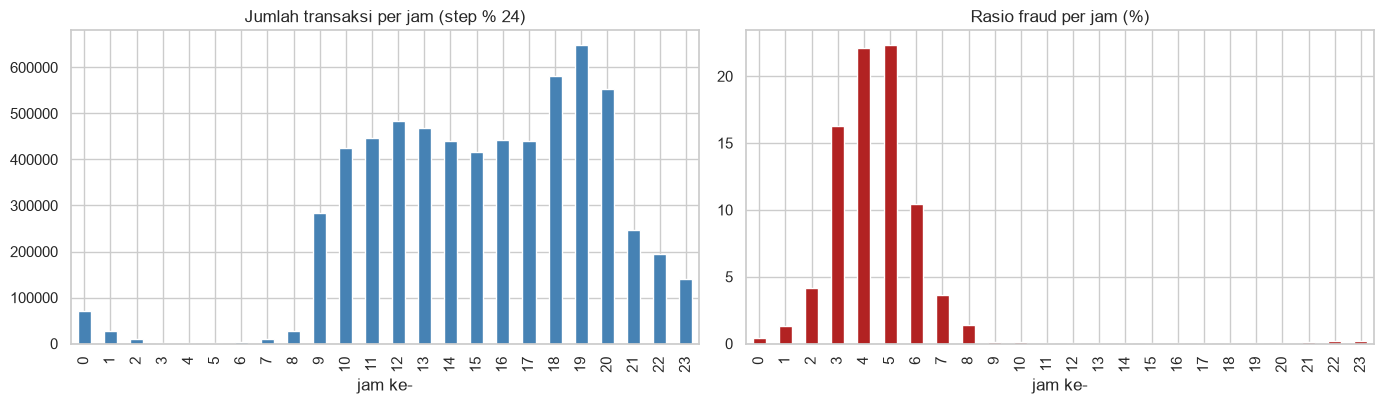

Rasio fraud tertinggi: jam ke-5 (22.303%)
Rasio fraud terendah : jam ke-19 (0.053%)


In [14]:
per_jam = df.groupby(df["step"] % 24)["isFraud"].agg(jumlah_transaksi="size", jumlah_fraud="sum", rasio_fraud="mean")
per_jam["rasio_fraud (%)"] = per_jam["rasio_fraud"] * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
per_jam["jumlah_transaksi"].plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Jumlah transaksi per jam (step % 24)")
ax[0].set_xlabel("jam ke-")
per_jam["rasio_fraud (%)"].plot.bar(ax=ax[1], color="firebrick")
ax[1].set_title("Rasio fraud per jam (%)")
ax[1].set_xlabel("jam ke-")
plt.tight_layout()
plt.show()

print(f"Rasio fraud tertinggi: jam ke-{per_jam['rasio_fraud (%)'].idxmax()} ({per_jam['rasio_fraud (%)'].max():.3f}%)")
print(f"Rasio fraud terendah : jam ke-{per_jam['rasio_fraud (%)'].idxmin()} ({per_jam['rasio_fraud (%)'].min():.3f}%)")

- **Temuan:** Volume transaksi normal mengikuti pola harian (ramai di jam tertentu, sepi di jam lain), sedangkan fraud cenderung tersebar lebih merata sepanjang hari.
- **Bukti:** Bar chart jumlah transaksi per jam tidak rata, sementara rasio fraud meningkat pada jam-jam ketika volume transaksi normal rendah (lihat grafik dan nilai tertinggi/terendah).
- **Interpretasi:** Pada jam sepi, transaksi fraud menjadi proporsi yang lebih besar sehingga waktu transaksi memberi informasi tambahan.
- **Implikasi:** Buat fitur `jam_dalam_hari = step % 24` (bagian 8).

### 5.6 Korelasi antarvariabel numerik (correlation heatmap)

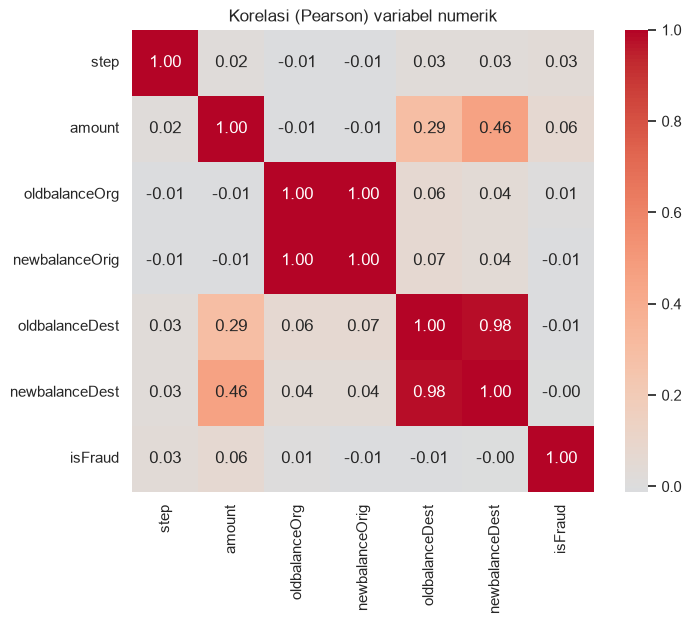

Korelasi oldbalanceOrg vs newbalanceOrig  : 0.999
Korelasi oldbalanceDest vs newbalanceDest : 0.977
Korelasi dengan isFraud:
amount            0.065
step              0.032
oldbalanceOrg     0.006
newbalanceDest   -0.001
oldbalanceDest   -0.006
newbalanceOrig   -0.010
Name: isFraud, dtype: float64


In [15]:
korelasi = df_s[kolom_numerik + ["isFraud"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Korelasi (Pearson) variabel numerik")
plt.show()

print(f"Korelasi oldbalanceOrg vs newbalanceOrig  : {korelasi.loc['oldbalanceOrg', 'newbalanceOrig']:.3f}")
print(f"Korelasi oldbalanceDest vs newbalanceDest : {korelasi.loc['oldbalanceDest', 'newbalanceDest']:.3f}")
print("Korelasi dengan isFraud:")
print(korelasi["isFraud"].drop("isFraud").sort_values(ascending=False).round(3))

- **Temuan:** Saldo sebelum dan sesudah transaksi berkorelasi sangat kuat (pengirim maupun penerima), sedangkan korelasi linear setiap variabel terhadap `isFraud` lemah.
- **Bukti:** Nilai korelasi pada heatmap dan output di atas.
- **Interpretasi:** Saldo lama dan baru membawa informasi yang hampir sama (multikolinearitas). Lemahnya korelasi linear dengan `isFraud` wajar karena fraud sangat langka dan polanya bersifat non-linear/kombinasi.
- **Implikasi:** Informasi yang berguna ada pada **hubungan** antarvariabel (selisih dan rasio), bukan pada nilai mentahnya; pertimbangkan model non-linear pada tahap berikutnya.

---
## 6. Data Quality Findings

In [16]:
n = len(df)
bukan_merchant = ~df["nameDest"].str.startswith("M")
selisih_asal = (df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]).abs()
selisih_tujuan = (df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]).abs()

temuan = [
    ("Missing value (NaN) — total sel", int(df.isna().sum().sum())),
    ("Baris duplikat penuh", int(df.duplicated().sum())),
    ("Nilai negatif pada kolom numerik", int((df[kolom_numerik] < 0).sum().sum())),
    ("amount = 0", int((df["amount"] == 0).sum())),
    ("oldbalanceOrg = 0 (saldo awal pengirim nol)", int((df["oldbalanceOrg"] == 0).sum())),
    ("newbalanceOrig = 0 (saldo akhir pengirim nol)", int((df["newbalanceOrig"] == 0).sum())),
    ("oldbalanceDest = 0 & newbalanceDest = 0 (saldo tujuan tak tercatat)",
     int(((df["oldbalanceDest"] == 0) & (df["newbalanceDest"] == 0)).sum())),
    ("Tujuan merchant (prefix 'M')", int((~bukan_merchant).sum())),
    ("Saldo pengirim tidak konsisten (|old - amount - new| > 0.01)", int((selisih_asal > 0.01).sum())),
    ("Saldo penerima tidak konsisten — hanya tujuan non-merchant",
     int(((selisih_tujuan > 0.01) & bukan_merchant).sum())),
]
kualitas = pd.DataFrame(temuan, columns=["Temuan", "Jumlah"])
kualitas["Persentase (%)"] = kualitas["Jumlah"] / n * 100
kualitas

,Temuan,Jumlah,Persentase (%)
0,Missing value (NaN) — total sel,0,0.000
1,Baris duplikat penuh,0,0.000
2,Nilai negatif pada kolom numerik,0,0.000
3,amount = 0,16,0.000
4,oldbalanceOrg = 0 (saldo awal pengirim nol),2102449,33.044
5,newbalanceOrig = 0 (saldo akhir pengirim nol),3609566,56.731
6,oldbalanceDest = 0 & newbalanceDest = 0 (saldo...,2317282,36.420
7,Tujuan merchant (prefix 'M'),2151495,33.815
8,Saldo pengirim tidak konsisten (|old - amount ...,5077691,79.805
9,Saldo penerima tidak konsisten — hanya tujuan ...,2037152,32.018


In [17]:
# --- Outlier (aturan IQR: nilai > Q3 + 1.5*IQR) ---
def ringkas_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    atas = q3 + 1.5 * (q3 - q1)
    return pd.Series({"batas_atas_IQR": atas, "jumlah_outlier": int((s > atas).sum()), "persen_outlier (%)": (s > atas).mean() * 100})


kolom_uang = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
outlier = df[kolom_uang].apply(ringkas_outlier).T
display(outlier)

# Apakah outlier amount berkaitan dengan fraud?
atas_amount = outlier.loc["amount", "batas_atas_IQR"]
print(f"Rasio fraud pada transaksi outlier amount : {df.loc[df['amount'] > atas_amount, 'isFraud'].mean() * 100:.3f}%")
print(f"Rasio fraud pada transaksi non-outlier    : {df.loc[df['amount'] <= atas_amount, 'isFraud'].mean() * 100:.3f}%")

,batas_atas_IQR,jumlah_outlier,persen_outlier (%)
amount,"501,719.339","338,078.000",5.314
oldbalanceOrg,"268,287.938","1,112,507.000",17.485
newbalanceOrig,"360,646.025","1,053,391.000",16.556
oldbalanceDest,"2,357,591.769","786,135.000",12.356
newbalanceDest,"2,779,773.125","738,527.000",11.607


Rasio fraud pada transaksi outlier amount : 1.140%
Rasio fraud pada transaksi non-outlier    : 0.072%


In [18]:
# --- Ketidakseimbangan kelas dan kualitas label ---
jumlah_kelas = df["isFraud"].value_counts().sort_index()
print("Distribusi isFraud:")
print(jumlah_kelas.rename({0: "normal", 1: "fraud"}))
print(f"Proporsi fraud : {jumlah_kelas.get(1, 0) / n * 100:.4f}%")
print(f"Rasio normal : fraud = {jumlah_kelas.get(0, 0) / max(jumlah_kelas.get(1, 1), 1):,.0f} : 1")

print("\nIsFlaggedFraud vs isFraud (aturan bisnis lama vs label sebenarnya):")
display(pd.crosstab(df["isFlaggedFraud"], df["isFraud"], margins=True))

Distribusi isFraud:
isFraud
normal    6354407
fraud        8213
Name: count, dtype: int64
Proporsi fraud : 0.1291%
Rasio normal : fraud = 774 : 1

IsFlaggedFraud vs isFraud (aturan bisnis lama vs label sebenarnya):


isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


**Ringkasan Data Quality Findings** *(cocokkan dengan angka pada output)*

1. **Missing value eksplisit:** umumnya tidak ada (`NaN` = 0). Namun terdapat **missing value tersembunyi**: saldo bernilai `0` pada `oldbalanceDest`/`newbalanceDest` (terutama untuk tujuan *merchant* yang saldonya tidak dicatat) dan `oldbalanceOrg = 0`. Nilai 0 ini bukan "saldo nol sebenarnya" pada semua kasus.
2. **Outlier:** `amount` dan kolom saldo memiliki banyak outlier menurut aturan IQR karena distribusi sangat miring. Rasio fraud pada kelompok outlier berbeda dari kelompok non-outlier, sehingga outlier mengandung informasi dan tidak boleh dibuang begitu saja.
3. **Inkonsistensi saldo:** sebagian transaksi tidak memenuhi persamaan `saldo_awal − amount = saldo_akhir`. Ini bisa menjadi sinyal berguna (fitur selisih saldo) sekaligus risiko *data leakage* karena berasal dari mekanisme simulasi.
4. **Ketidakseimbangan kelas ekstrem:** fraud hanya sebagian kecil dari seluruh data → akurasi tidak bermakna; perlu *stratified split*, penanganan imbalance, dan metrik Precision/Recall/PR-AUC.
5. **`isFlaggedFraud`** hanya menandai sangat sedikit transaksi dan hampir tidak menangkap fraud yang ada → tidak layak dijadikan fitur utama (dan dapat membocorkan aturan simulasi).
6. **Kolom ID** (`nameOrig`, `nameDest`) berkardinalitas sangat tinggi dan hampir unik per baris → tidak dipakai langsung.
7. **Data sintetis:** pola fraud berasal dari simulator sehingga hasil model tidak otomatis mencerminkan performa pada data dunia nyata.

---
## 7. Preprocessing Plan

Berdasarkan Data Understanding dan EDA. Format: *apa masalahnya + mengapa penting + bagaimana rencana penanganannya*.

| Masalah | Variabel | Rencana Penanganan | Alasan |
|---|---|---|---|
| **Missing value** (eksplisit) | semua kolom | Verifikasi tidak ada `NaN`; sediakan *imputer* median pada pipeline sebagai pengaman. | Banyak algoritma gagal jika ada `NaN`; pengaman memastikan pipeline tetap berjalan bila data baru bermasalah. |
| **Missing value tersembunyi** (saldo = 0) | `oldbalanceDest`, `newbalanceDest`, `oldbalanceOrg` | Pertahankan nilai 0, tambahkan fitur penanda (`tujuan_merchant`, `saldo_asal_terkuras`); tidak diimputasi. | Nilai 0 pada merchant berarti "tidak dicatat", sedangkan 0 pada akun pelanggan bisa berarti saldo kosong; menghapusnya akan menghilangkan informasi penting. |
| **Outlier** | `amount`, seluruh kolom saldo | **Tidak dibuang.** Terapkan `log1p` lalu `RobustScaler`. | Outlier berkaitan dengan fraud (bagian 5 dan 6); `log1p` meredam kemiringan ekstrem, `RobustScaler` memakai median/IQR sehingga tahan outlier. |
| **Data kategorikal** | `type` | *One-hot encoding* (5 kategori, tanpa urutan). | Model tidak dapat memakai teks; kategori tidak berurutan sehingga *label encoding* menyesatkan. |
| **Data kategorikal berkardinalitas tinggi** | `nameOrig`, `nameDest` | Dihapus dari fitur; hanya diambil informasi turunan (prefix merchant `M`). | ID hampir unik per baris → berisiko *overfitting* dan tidak dapat digeneralisasi. |
| **Perbedaan skala** | `amount`, saldo (jutaan) vs `step`/jam (0–23) | Skala fitur uang dengan `RobustScaler` setelah `log1p`; fitur biner dibiarkan. | Skala yang jauh berbeda mendominasi model berbasis jarak/gradien. |
| **Ketidakseimbangan kelas** | `isFraud` | *Stratified* train–test split; penanganan imbalance (mis. `class_weight`) **hanya pada data latih** pada tahap modeling. | Menjaga proporsi fraud di kedua subset dan mencegah kebocoran data uji. |
| **Risiko data leakage** | `isFlaggedFraud`, fitur selisih saldo | Buang `isFlaggedFraud`; periksa dominasi fitur selisih saldo saat evaluasi. | Variabel turunan aturan/simulator dapat membuat performa tampak terlalu bagus. |
| **Lingkup data** | `type` | Fokus ke `TRANSFER` dan `CASH_OUT` (satu-satunya tipe yang memuat fraud). | Mengurangi ukuran data dan *noise* tanpa kehilangan kasus fraud. |

---
## 8. Initial Feature Engineering

Usulan fitur baru (minimal 2 diminta; berikut 6 kandidat):

| Kandidat Fitur | Dibentuk dari | Alasan |
|---|---|---|
| `selisih_saldo_asal` | `oldbalanceOrg − amount − newbalanceOrig` | Mendeteksi saldo pengirim yang tidak konsisten dengan nominal transaksi. |
| `selisih_saldo_tujuan` | `oldbalanceDest + amount − newbalanceDest` | Mendeteksi saldo penerima yang tidak bertambah sesuai nominal (indikasi dana "dinolkan"/dipindah). |
| `rasio_amount_saldo_asal` | `amount / oldbalanceOrg` (0 jika saldo awal 0) | Menangkap perilaku menguras saldo (rasio ≈ 1). |
| `saldo_asal_terkuras` | `oldbalanceOrg > 0` dan `newbalanceOrig == 0` | Penanda biner akun pengirim dikosongkan seluruhnya. |
| `tujuan_merchant` | prefix `nameDest` = `M` | Fraud tidak menyasar merchant; sekaligus penanda saldo tujuan tak tercatat. |
| `jam_dalam_hari` | `step % 24` | Menangkap pola waktu harian (bagian 5.5). |

In [19]:
def tambah_fitur(data):
    d = data.copy()
    d["selisih_saldo_asal"] = d["oldbalanceOrg"] - d["amount"] - d["newbalanceOrig"]
    d["selisih_saldo_tujuan"] = d["oldbalanceDest"] + d["amount"] - d["newbalanceDest"]
    d["rasio_amount_saldo_asal"] = np.where(d["oldbalanceOrg"] > 0, d["amount"] / d["oldbalanceOrg"].where(d["oldbalanceOrg"] > 0, 1), 0.0)
    d["saldo_asal_terkuras"] = ((d["oldbalanceOrg"] > 0) & (d["newbalanceOrig"] == 0)).astype(int)
    d["tujuan_merchant"] = d["nameDest"].str.startswith("M").astype(int)
    d["jam_dalam_hari"] = d["step"] % 24
    return d


fitur_baru = [
    "selisih_saldo_asal", "selisih_saldo_tujuan", "rasio_amount_saldo_asal",
    "saldo_asal_terkuras", "tujuan_merchant", "jam_dalam_hari",
]

df_fe = tambah_fitur(df[df["type"].isin(["TRANSFER", "CASH_OUT"])])
perbandingan = df_fe.groupby("isFraud")[fitur_baru].agg(["mean", "median"]).T
perbandingan.columns = [f"isFraud={c}" for c in perbandingan.columns]
perbandingan

isFraud=0   isFraud=1
selisih_saldo_asal      mean   -286,803.510 -10,692.325
                        median -144,200.825       0.000
selisih_saldo_tujuan    mean    -30,910.325 732,509.301
                        median        0.000   2,231.460
rasio_amount_saldo_asal mean        145.973       0.994
                        median        0.220       1.000
saldo_asal_terkuras     mean          0.427       0.976
                        median        0.000       1.000
tujuan_merchant         mean          0.000       0.000
                        median        0.000       0.000
jam_dalam_hari          mean         15.320      11.546
                        median       16.000      12.000

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(data=df_fe, x=df_fe["rasio_amount_saldo_asal"].clip(upper=2), hue="isFraud",
             stat="density", common_norm=False, bins=50, ax=ax[0])
ax[0].set_title("rasio_amount_saldo_asal (dipotong di 2)")

sns.barplot(data=df_fe, x="type", y="saldo_asal_terkuras", hue="isFraud", ax=ax[1])
ax[1].set_title("Proporsi saldo_asal_terkuras per type & kelas")
plt.tight_layout()
plt.show()

- **Temuan:** Fitur turunan memisahkan kedua kelas lebih jelas daripada nilai mentah: rasio `amount/saldo awal` pada fraud menumpuk di sekitar 1, dan proporsi akun yang terkuras jauh lebih tinggi pada fraud.
- **Bukti:** Tabel perbandingan *mean/median* per kelas serta histogram dan bar chart di atas.
- **Interpretasi:** Pola "kosongkan akun sekaligus" dan ketidakkonsistenan saldo memang lebih informatif daripada nominal absolut.
- **Implikasi:** Fitur dipakai pada pipeline awal. Fitur selisih saldo dapat sangat dominan karena berasal dari mekanisme simulator — **harus diperiksa kemungkinan *leakage* saat modeling**.

---
## 9. Initial Data Pipeline

Alur: filter lingkup (`TRANSFER`, `CASH_OUT`) → tambah fitur → pilih fitur → *stratified split* 80/20 →
transformasi (`log1p`, signed-log, `RobustScaler`, *one-hot*). Transformasi **di-*fit* hanya pada data latih** untuk mencegah kebocoran.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler

LINGKUP_TIPE = ["TRANSFER", "CASH_OUT"]

fitur_uang = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
fitur_selisih = ["selisih_saldo_asal", "selisih_saldo_tujuan"]
fitur_rasio = ["rasio_amount_saldo_asal"]
fitur_biner_waktu = ["saldo_asal_terkuras", "tujuan_merchant", "jam_dalam_hari"]
fitur_kategori = ["type"]
semua_fitur = fitur_uang + fitur_selisih + fitur_rasio + fitur_biner_waktu + fitur_kategori


def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def potong_rasio(x):
    return np.clip(x, 0, 10)


def bangun_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("uang", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("scaler", RobustScaler()),
            ]), fitur_uang),
            ("selisih", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("slog", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                ("scaler", RobustScaler()),
            ]), fitur_selisih),
            ("rasio", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("clip", FunctionTransformer(potong_rasio, feature_names_out="one-to-one")),
                ("scaler", RobustScaler()),
            ]), fitur_rasio),
            ("biner_waktu", "passthrough", fitur_biner_waktu),
            ("kategori", OneHotEncoder(handle_unknown="ignore", sparse_output=False), fitur_kategori),
        ],
        remainder="drop",   # nameOrig, nameDest, step, isFlaggedFraud dibuang
        verbose_feature_names_out=False,
    )


def siapkan_data(data, test_size=0.2, random_state=RANDOM_STATE):
    """Pipeline data awal: filter -> fitur -> split -> transformasi (fit hanya pada data latih)."""
    d = data[data["type"].isin(LINGKUP_TIPE)]
    d = tambah_fitur(d)
    X, y = d[semua_fitur], d["isFraud"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, stratify=y, random_state=random_state)
    pre = bangun_preprocessor()
    X_tr_p = pre.fit_transform(X_tr)
    X_te_p = pre.transform(X_te)
    nama_fitur = list(pre.get_feature_names_out())
    return X_tr_p, X_te_p, y_tr, y_te, pre, nama_fitur


X_train_p, X_test_p, y_train, y_test, preprocessor, nama_fitur = siapkan_data(df)

print("Bentuk X_train :", X_train_p.shape)
print("Bentuk X_test  :", X_test_p.shape)
print(f"Proporsi fraud — train: {y_train.mean() * 100:.4f}% | test: {y_test.mean() * 100:.4f}%")
print("Ada NaN di X_train?", bool(np.isnan(X_train_p).any()), "| di X_test?", bool(np.isnan(X_test_p).any()))
print("\nDaftar fitur akhir:", nama_fitur)

pd.DataFrame(X_train_p[:5], columns=nama_fitur)

Bentuk X_train : (2216327, 13)
Bentuk X_test  : (554082, 13)
Proporsi fraud — train: 0.2964% | test: 0.2965%
Ada NaN di X_train? False | di X_test? False

Daftar fitur akhir: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'selisih_saldo_asal', 'selisih_saldo_tujuan', 'rasio_amount_saldo_asal', 'saldo_asal_terkuras', 'tujuan_merchant', 'jam_dalam_hari', 'type_CASH_OUT', 'type_TRANSFER']


,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,selisih_saldo_asal,selisih_saldo_tujuan,rasio_amount_saldo_asal,saldo_asal_terkuras,tujuan_merchant,jam_dalam_hari,type_CASH_OUT,type_TRANSFER
0,-0.665,-0.553,0.000,0.105,-0.017,0.410,0.010,-0.036,0.000,0.000,15.000,1.000,0.000
1,0.202,0.664,11.184,0.285,0.277,7.043,-0.010,0.080,0.000,0.000,22.000,1.000,0.000
2,0.389,0.063,0.000,-0.187,-0.150,-0.404,-0.000,1.503,1.000,0.000,17.000,1.000,0.000
3,0.255,0.339,0.000,-0.471,-0.387,-0.276,-0.000,1.503,1.000,0.000,15.000,1.000,0.000
4,0.095,-0.553,0.000,0.857,1.001,-0.178,0.010,-0.036,0.000,0.000,18.000,1.000,0.000


**Catatan pipeline:** proporsi fraud pada data latih dan uji hampir sama (hasil *stratified split*), tidak ada `NaN` setelah transformasi,
dan seluruh transformasi hanya mempelajari statistik dari data latih. Fungsi `siapkan_data()` dapat dipanggil ulang pada tahap UTS/UAS.

---
## 10. Kesimpulan dan Rencana Tahap Berikutnya

### Jawaban lima pertanyaan Standar Hasil Tahap 2

1. **Masalah** — Mendeteksi aktivitas transaksi digital yang tidak wajar (*fraud*) yang sangat langka di antara jutaan transaksi normal.
2. **Data** — Dataset PaySim (Kaggle, ±6,3 juta transaksi, 11 variabel, target `isFraud`). Sesuai karena berisi transaksi digital berlabel, bervariabel jelas, dan berukuran besar; terbatas karena bersifat sintetis.
3. **Temuan** — (a) fraud hanya terjadi pada `TRANSFER` dan `CASH_OUT`; (b) fraud sangat langka (kelas tidak seimbang); (c) `amount` dan saldo sangat miring dengan banyak outlier yang justru berkaitan dengan fraud; (d) fraud cenderung menguras seluruh saldo pengirim; (e) saldo lama–baru berkorelasi sangat kuat sehingga informasi terletak pada selisih/rasio.
4. **Persiapan** — Missing value tersembunyi (saldo 0), outlier, kategori, perbedaan skala, imbalance, dan risiko leakage telah dipetakan beserta rencana penanganannya (bagian 7) dan sebagian sudah diimplementasikan di pipeline awal (bagian 9).
5. **Fitur** — `selisih_saldo_asal`, `selisih_saldo_tujuan`, `rasio_amount_saldo_asal`, `saldo_asal_terkuras`, `tujuan_merchant`, `jam_dalam_hari`, ditambah `type` (one-hot) dan fitur uang yang di-`log1p` + `RobustScaler`.

### Rencana tahap berikutnya (belum dikerjakan pada Task 02)
- Membuat *baseline* model klasifikasi dan membandingkannya dengan pendekatan *anomaly detection* (mis. Isolation Forest).
- Mengevaluasi dengan Precision, Recall, F1, dan PR-AUC; memakai *stratified cross-validation*.
- Menangani ketidakseimbangan kelas **hanya pada data latih** (mis. `class_weight`, *resampling*).
- Menguji kemungkinan *leakage* pada fitur selisih saldo (mis. dengan dan tanpa fitur tersebut) serta mempertimbangkan pemisahan berbasis waktu (`step`).
- Menyimpan hasil ke repository kelompok untuk dilanjutkan pada UTS dan UAS.

### Keterbatasan
Data bersifat sintetis dari simulator sehingga pola fraud lebih "bersih" dibanding dunia nyata; hasil model perlu diinterpretasikan dengan hati-hati.

---
## 11. Pertemuan 4 - Pengembangan Model dan Eksperimen

Tahap ini mempertahankan baseline dari Pertemuan 3 dan membandingkannya dengan dua kandidat model.

1. **Baseline:** Logistic Regression dengan `class_weight="balanced"`.
2. **Kandidat 1:** Decision Tree dengan pembatasan kedalaman untuk menangkap pola non-linear.
3. **Kandidat 2:** Random Forest sebagai ensemble Bagging yang menggabungkan banyak pohon.

Karena fraud sangat jarang, metrik utama adalah Precision, Recall, F1-score, PR-AUC, dan confusion matrix. Accuracy hanya menjadi informasi tambahan.


In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.tree import DecisionTreeClassifier

model_baseline = LogisticRegression(class_weight="balanced", max_iter=200, solver="lbfgs", random_state=RANDOM_STATE)
model_kandidat_1 = DecisionTreeClassifier(class_weight="balanced", max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE)
model_kandidat_2 = RandomForestClassifier(n_estimators=100, class_weight="balanced", max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)

model_baseline.fit(X_train_p, y_train)
model_kandidat_1.fit(X_train_p, y_train)
model_kandidat_2.fit(X_train_p, y_train)

model_models = {
    "Logistic Regression (baseline)": model_baseline,
    "Decision Tree (kandidat 1)": model_kandidat_1,
    "Random Forest (kandidat 2)": model_kandidat_2,
}

hasil_model = []
prediksi_model = {}
for nama, model in model_models.items():
    proba = model.predict_proba(X_test_p)[:, 1]
    pred = (proba >= 0.5).astype(int)
    prediksi_model[nama] = {"pred": pred, "proba": proba}
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    print(f"\n{nama}")
    print(classification_report(y_test, pred, target_names=["normal", "fraud"], zero_division=0))
    print(f"Confusion matrix: TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}")
    hasil_model.append({
        "Model": nama, "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

perbandingan_model = pd.DataFrame(hasil_model).set_index("Model")
display(perbandingan_model.round(4))



Logistic Regression (baseline)
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00    552439
       fraud       0.51      0.99      0.67      1643

    accuracy                           1.00    554082
   macro avg       0.76      1.00      0.84    554082
weighted avg       1.00      1.00      1.00    554082

Confusion matrix: TN=550,873, FP=1,566, FN=9, TP=1,634

Decision Tree (kandidat 1)
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00    552439
       fraud       0.90      1.00      0.95      1643

    accuracy                           1.00    554082
   macro avg       0.95      1.00      0.97    554082
weighted avg       1.00      1.00      1.00    554082

Confusion matrix: TN=552,261, FP=178, FN=4, TP=1,639

Random Forest (kandidat 2)
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00    552439
       fraud       0.97      1.00      0.

,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC
Model,,,,,,
Logistic Regression (baseline),0.997,0.511,0.995,0.675,0.993,0.998
Decision Tree (kandidat 1),1.000,0.902,0.998,0.947,0.998,0.999
Random Forest (kandidat 2),1.000,0.974,0.997,0.985,0.998,0.998


### 11.1 Temuan Awal

Gunakan output evaluasi sebagai bukti untuk membandingkan model. Accuracy tidak dijadikan dasar utama karena proporsi fraud sangat kecil. Recall mengukur fraud yang berhasil ditemukan, Precision mengukur ketepatan alarm, F1 menyeimbangkan keduanya, dan PR-AUC sesuai untuk kelas positif yang langka.

**Rencana lanjutan:** tuning threshold sesuai biaya False Positive/False Negative, validasi berbasis waktu, pengujian dengan dan tanpa fitur selisih saldo, serta tuning hyperparameter model terbaik.
